In [1]:
# === Ô GHI LOG (mẫu PL1 bản 2 – chạy được với ipykernel 7): mọi thứ in ra màn hình đồng thời được ghi vào file log ===
import logging, sys, datetime, warnings
from pathlib import Path
TEN_NOTEBOOK = "01_cleaning"
NGUOI_CHAY   = "Han"

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").exists())  # thư mục gốc repo
thu_muc_log = ROOT / "logs" / "tien_xu_ly_log"
thu_muc_log.mkdir(parents=True, exist_ok=True)
file_log = thu_muc_log / f"{datetime.datetime.now():%Y-%m-%d_%H%M}_{TEN_NOTEBOOK}.log"
tep_log = open(file_log, "a", encoding="utf-8", buffering=1)

if hasattr(sys.stdout, "echo"):                  # chạy trong Jupyter / VS Code: nhờ kernel chép thêm ra file, không thay sys.stdout
    sys.stdout.echo = tep_log
    sys.stderr.echo = tep_log
else:                                            # chạy bằng python thường
    class GhiCaHai:
        def __init__(self, man_hinh, tep): self.man_hinh, self.tep = man_hinh, tep
        def write(self, s): self.man_hinh.write(s); self.tep.write(s); return len(s)
        def flush(self): self.man_hinh.flush(); self.tep.flush()
        def __getattr__(self, ten): return getattr(self.man_hinh, ten)
    sys.stdout = GhiCaHai(sys.__stdout__, tep_log)

logging.basicConfig(stream=sys.stdout, level=logging.INFO, force=True,
                    format="%(asctime)s | %(levelname)s | %(message)s", datefmt="%Y-%m-%d %H:%M:%S")
logging.captureWarnings(True)
log = logging.getLogger(TEN_NOTEBOOK)
log.info(f"Bắt đầu chạy {TEN_NOTEBOOK} – người chạy: {NGUOI_CHAY} – file log: {file_log}")

2026-11-13 19:40:49 | INFO | Bắt đầu chạy 01_cleaning – người chạy: Han – file log: /Users/caongochan/Documents/Nhom11_DuBaoDienNang_GiuaKy/logs/2026-11-13_1940_01_cleaning.log


Số dòng: 2.075.259 | Số cột: 9
Khớp Proposal: True
Dòng trùng lặp hoàn toàn: 0 | Mốc thời gian trùng: 0
Global_active_power      float64
Global_reactive_power    float64
Voltage                  float64
Global_intensity         float64
Sub_metering_1           float64
Sub_metering_2           float64
Sub_metering_3           float64
dtype: object
Mốc đầu: 2006-12-16 17:24:00 | Mốc cuối: 2010-11-26 21:02:00
Số phút lý thuyết: 2.075.259 | Số dòng có trong tệp: 2.075.259
Số mốc phút vắng mặt hoàn toàn: 0
Thiếu theo cột:
 Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64
Số cột bị thiếu trong mỗi dòng:
 0    2049280
7      25979
Name: count, dtype: int64
Chỉ có 2 trạng thái (đủ cả 7 cột hoặc thiếu cả 7 cột): True
Số khoảng thiếu: 71 | Dài nhất: 7226 phút (120.4 giờ)
Khoảng thiếu <= 60 phút: 62 | > 120 phút: 7
Côn

# 01_cleaning: Kiểm soát chất lượng, xử lý thiếu và tổng hợp theo giờ
**Người thực hiện:** Cao Ngọc Hân (Ngày 2)

**Đầu vào:** `data/raw/household_power_consumption.txt` (tệp gốc UCI, không chỉnh sửa)

**Đầu ra:**
- `data/processed/hourly_clean.csv`: dữ liệu theo giờ, giao cho Nhung và Linh
- `data/tien_xu_ly_data/quality_control_table.csv` và `.md`: bảng kiểm soát chất lượng (mục 4.1 báo cáo)
- `data/tien_xu_ly_data/missing_gaps_top10.csv`: 10 khoảng thiếu dài nhất
- `figures/tien_xu_ly_figures/01_boxplot_raw.png`, `figures/tien_xu_ly_figures/01_missing_gaps.png`: hình gốc

**Nguyên tắc:** không tạo dữ liệu giả; không điền nhãn mục tiêu bị thiếu; không điền trung vị ở bước này (việc đó thuộc pipeline mô hình, fit trên Train, để tránh rò rỉ dữ liệu); ngoại lệ chỉ đánh dấu và nhận xét, không xóa.

## 0. Cấu hình và hàm hỗ trợ

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Thư mục gốc repo (chạy được cả khi mở notebook trong notebooks/ hoặc ở thư mục gốc)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").exists())
RAW = ROOT / "data" / "raw" / "household_power_consumption.txt"
DIR_DATA = ROOT / "data" / "tien_xu_ly_data"
DIR_PROC = ROOT / "data" / "processed"
DIR_FIG = ROOT / "figures" / "tien_xu_ly_figures"
for p in (DIR_PROC, DIR_FIG):
    p.mkdir(parents=True, exist_ok=True)

MEAN_COLS = ["Global_active_power", "Global_reactive_power", "Voltage", "Global_intensity"]
SUB_COLS = ["Sub_metering_1", "Sub_metering_2", "Sub_metering_3"]
COLS = MEAN_COLS + SUB_COLS          # 7 cột đo
TARGET = "Global_active_power"

# ---- Các quy tắc/ngưỡng (cả nhóm đã thống nhất, đổi ở đây nếu nhóm đổi ý) ----
MIN_VALID_MIN = 30      # một giờ chỉ hợp lệ nếu có >= 30/60 phút đo được
MAX_FFILL_H = 2         # điền tiến tối đa 2 giờ cho ĐẦU VÀO
VOLT_RANGE = (200, 260) # ngưỡng kiểm tra miền giá trị của Voltage (V), lưới điện Pháp ~230 V
PROPOSAL_ROWS = 2_075_259
SEED = 42

qc = []  # bảng kiểm soát chất lượng
def add_qc(check, result, handling, reason):
    qc.append({"Kiểm tra": check, "Kết quả (số thật)": result,
               "Cách xử lý": handling, "Lý do": reason})

def runs(mask):
    """Tìm các đoạn True liên tiếp. Trả về (chỉ số bắt đầu, độ dài)."""
    m = np.concatenate(([0], np.asarray(mask).astype(np.int8), [0]))
    d = np.diff(m)
    starts = np.where(d == 1)[0]
    ends = np.where(d == -1)[0]
    return starts, ends - starts

def fmt(n):
    return f"{int(n):,}".replace(",", ".")

## 1. Đọc dữ liệu gốc
Tệp dùng dấu `;` để phân cách, giá trị thiếu là ký tự `?`. Gộp Date và Time thành một cột thời gian.

In [3]:
raw = pd.read_csv(RAW, sep=";", na_values=["?"], low_memory=False)
n_rows_raw, n_cols_raw = raw.shape
print("Số dòng:", fmt(n_rows_raw), "| Số cột:", n_cols_raw)
print("Khớp Proposal:", n_rows_raw == PROPOSAL_ROWS)

dup_full = int(raw.duplicated().sum())
raw["datetime"] = pd.to_datetime(raw["Date"] + " " + raw["Time"], format="%d/%m/%Y %H:%M:%S")
dup_ts = int(raw["datetime"].duplicated().sum())
print("Dòng trùng lặp hoàn toàn:", dup_full, "| Mốc thời gian trùng:", dup_ts)

df = raw.drop(columns=["Date", "Time"]).set_index("datetime").sort_index()
del raw
if dup_ts > 0:
    df = df[~df.index.duplicated(keep="first")]
df.head()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
datetime,,,,,,,
2006-12-16 17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
2006-12-16 17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2006-12-16 17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
2006-12-16 17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
2006-12-16 17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


## 2. Kiểm tra số dòng, số cột, kiểu dữ liệu, trùng lặp

In [4]:
print(df.dtypes)
add_qc("Số dòng, số cột thực tế",
       f"{fmt(n_rows_raw)} dòng, {n_cols_raw} cột. " + ("Khớp" if n_rows_raw == PROPOSAL_ROWS else "KHÁC") + f" với Proposal ({fmt(PROPOSAL_ROWS)} dòng)",
       "Giữ nguyên", "Tự đếm bằng code để đối chiếu, không chép số từ Proposal")
add_qc("Kiểu dữ liệu, định dạng",
       "7 cột đo đọc thành số thực (float64); Date và Time là chuỗi, đã gộp thành datetime theo định dạng dd/mm/yyyy hh:mm:ss",
       "Chuyển ký tự '?' thành NaN; gộp Date và Time thành chỉ mục thời gian",
       "Mô hình và resample cần kiểu số và kiểu thời gian")
add_qc("Dòng trùng lặp",
       f"{dup_full} dòng trùng hoàn toàn; {dup_ts} mốc thời gian bị lặp",
       "Không có gì cần xóa" if (dup_full == 0 and dup_ts == 0) else "Giữ dòng đầu tiên của mỗi mốc thời gian",
       "Dòng lặp làm sai thống kê và sai khi tổng hợp theo giờ")

## 3. Tính liên tục của thời gian
Dữ liệu ghi mỗi phút. Kiểm tra có mốc phút nào vắng mặt hẳn trong tệp không (khác với mốc có mặt nhưng giá trị là `?`).

In [5]:
first, last = df.index.min(), df.index.max()
full_idx = pd.date_range(first, last, freq="min")
absent = full_idx.difference(df.index)
print("Mốc đầu:", first, "| Mốc cuối:", last)
print("Số phút lý thuyết:", fmt(len(full_idx)), "| Số dòng có trong tệp:", fmt(len(df)))
print("Số mốc phút vắng mặt hoàn toàn:", fmt(len(absent)))

add_qc("Tính liên tục thời gian",
       f"Từ {first:%d/%m/%Y %H:%M} đến {last:%d/%m/%Y %H:%M}: cần {fmt(len(full_idx))} mốc phút, tệp có {fmt(len(df))}; thiếu hẳn {fmt(len(absent))} mốc",
       "Dựng lại trục thời gian đầy đủ theo phút; mốc vắng mặt (nếu có) được coi là thiếu dữ liệu" if len(absent) else "Không cần xử lý, trục thời gian đã đầy đủ",
       "Trục thời gian liên tục là điều kiện để tạo lag, rolling đúng nghĩa")

# Trục phút đầy đủ, dùng cho các bước sau
frame = df.reindex(full_idx)
frame.index.name = "datetime"

## 4. Giá trị thiếu (`?`)
Câu hỏi cần trả lời: thiếu bao nhiêu, có thiếu đồng thời ở cả 7 cột không, các khoảng thiếu liên tục dài bao lâu.

In [6]:
na_cnt = df[COLS].isna().sum()
na_total_rows = int(df[COLS].isna().any(axis=1).sum())
na_per_row = df[COLS].isna().sum(axis=1)
dist = na_per_row.value_counts().sort_index()
simultaneous = set(dist.index.tolist()) <= {0, len(COLS)}
print("Thiếu theo cột:\n", na_cnt)
print("Số cột bị thiếu trong mỗi dòng:\n", dist)
print("Chỉ có 2 trạng thái (đủ cả 7 cột hoặc thiếu cả 7 cột):", simultaneous)

# Khoảng thiếu liên tục theo phút (tính cả mốc vắng mặt)
mask_min = frame[COLS].isna().all(axis=1).to_numpy()
st, ln = runs(mask_min)
gaps = pd.DataFrame({
    "bat_dau": frame.index[st],
    "ket_thuc": frame.index[st + ln - 1],
    "so_phut": ln,
})
gaps["so_gio"] = (gaps["so_phut"] / 60).round(2)
top10 = gaps.sort_values("so_phut", ascending=False).head(10).reset_index(drop=True)
top10.to_csv(DIR_DATA / "missing_gaps_top10.csv", index=False)
n_gaps = len(gaps)
longest = int(gaps["so_phut"].max()) if n_gaps else 0
n_gap_gt120 = int((gaps["so_phut"] > 120).sum())
n_gap_le60 = int((gaps["so_phut"] <= 60).sum())
print(f"Số khoảng thiếu: {n_gaps} | Dài nhất: {longest} phút ({longest/60:.1f} giờ)")
print(f"Khoảng thiếu <= 60 phút: {n_gap_le60} | > 120 phút: {n_gap_gt120}")
top10

,bat_dau,ket_thuc,so_phut,so_gio
0,2010-08-17 21:02:00,2010-08-22 21:27:00,7226,120.43
1,2010-09-25 03:56:00,2010-09-28 19:12:00,5237,87.28
2,2007-04-28 00:21:00,2007-04-30 14:23:00,3723,62.05
3,2009-06-13 00:30:00,2009-06-15 07:34:00,3305,55.08
4,2010-01-12 14:53:00,2010-01-14 19:01:00,3129,52.15
5,2010-03-20 03:52:00,2010-03-21 13:38:00,2027,33.78
6,2009-08-13 05:00:00,2009-08-13 19:50:00,891,14.85
7,2007-07-15 16:49:00,2007-07-15 18:11:00,83,1.38
8,2008-12-10 10:48:00,2008-12-10 11:57:00,70,1.17
9,2007-07-15 18:21:00,2007-07-15 19:07:00,47,0.78


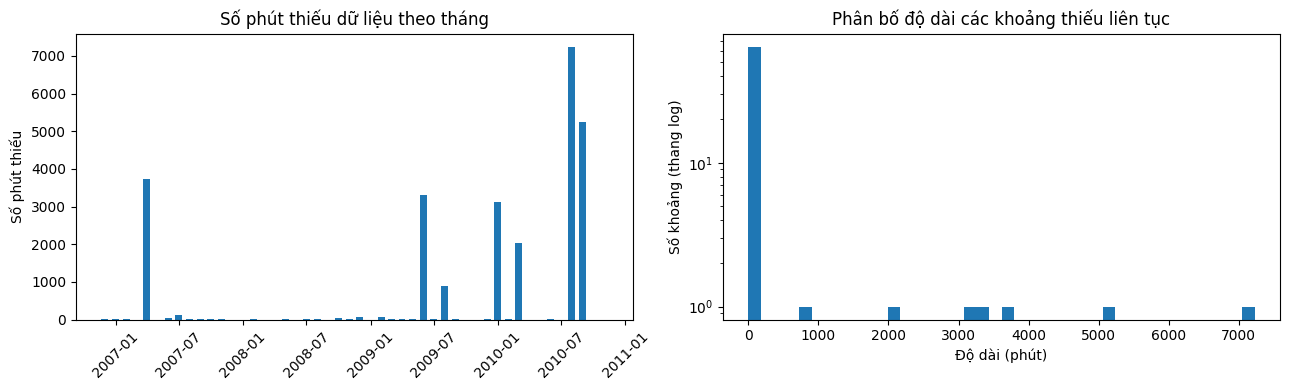

In [7]:
add_qc("Giá trị thiếu ('?')",
       f"Mỗi cột đo thiếu {fmt(na_cnt.iloc[0])} giá trị ({na_cnt.iloc[0]/n_rows_raw*100:.3f}%)"
       + ("; cả 7 cột thiếu đồng thời trên cùng một dòng" if simultaneous else "; các cột KHÔNG thiếu đồng thời, cần xem lại")
       + f". Có {fmt(n_gaps)} khoảng thiếu liên tục, dài nhất {fmt(longest)} phút (~{longest/60:.1f} giờ); {fmt(n_gap_gt120)} khoảng dài hơn 2 giờ",
       "Không điền nhãn mục tiêu. Với đầu vào: điền tiến tối đa 2 giờ, thêm cờ báo thiếu; phần còn lại giữ NaN (Nhung điền trung vị học từ Train trong pipeline mô hình)",
       "Điền nhãn sẽ làm sai kết quả đánh giá. Điền tiến chỉ dùng quá khứ nên không rò rỉ. Khoảng thiếu dài (nhiều giờ, nhiều ngày) không thể điền hợp lý")

# Hình: thiếu theo tháng và phân bố độ dài khoảng thiếu
miss_by_month = pd.Series(mask_min, index=frame.index).resample("MS").sum()
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(miss_by_month.index, miss_by_month.values, width=20)
ax[0].set_title("Số phút thiếu dữ liệu theo tháng")
ax[0].set_ylabel("Số phút thiếu"); ax[0].tick_params(axis="x", rotation=45)
ax[1].hist(gaps["so_phut"], bins=40, log=True)
ax[1].set_title("Phân bố độ dài các khoảng thiếu liên tục")
ax[1].set_xlabel("Độ dài (phút)"); ax[1].set_ylabel("Số khoảng (thang log)")
plt.tight_layout()
plt.savefig(DIR_FIG / "01_missing_gaps.png", dpi=150)
plt.show()

## 5. Miền giá trị hợp lý
Kiểm tra công suất, dòng điện, Sub_metering không âm; Voltage nằm trong ngưỡng hợp lý; và một phép kiểm tra nhất quán vật lý: điện năng ba công tơ phụ không được lớn hơn tổng điện năng của cả hộ trong cùng phút (`Global_active_power × 1000 / 60` Wh).

In [8]:
neg_power = int((frame[["Global_active_power", "Global_reactive_power"]] < 0).sum().sum())
neg_int = int((frame["Global_intensity"] < 0).sum())
neg_sub = int((frame[SUB_COLS] < 0).sum().sum())
zero_gap = int((frame[TARGET] == 0).sum())
volt_out = int(((frame["Voltage"] < VOLT_RANGE[0]) | (frame["Voltage"] > VOLT_RANGE[1])).sum())
rem = frame[TARGET] * 1000 / 60 - frame[SUB_COLS].sum(axis=1)   # phần điện không qua 3 công tơ phụ
neg_rem = int((rem < 0).sum())
print("Công suất âm:", neg_power, "| Intensity âm:", neg_int, "| Sub_metering âm:", neg_sub)
print("Global_active_power = 0:", zero_gap)
print(f"Voltage ngoài [{VOLT_RANGE[0]}, {VOLT_RANGE[1]}] V:", volt_out)
print("Phút mà tổng 3 công tơ phụ > tổng điện năng cả hộ:", neg_rem)
print(frame[COLS].agg(["min", "max"]).T)

In [9]:
add_qc("Miền giá trị hợp lý",
       f"Công suất âm: {neg_power}; Global_intensity âm: {neg_int}; Sub_metering âm: {neg_sub}; Global_active_power = 0: {fmt(zero_gap)} phút; "
       f"Voltage ngoài [{VOLT_RANGE[0]}, {VOLT_RANGE[1]}] V: {fmt(volt_out)} phút; "
       f"phút có tổng 3 công tơ phụ lớn hơn điện năng cả hộ: {fmt(neg_rem)}",
       "Chỉ ghi nhận, không xóa. Nếu có giá trị vi phạm thì nhận xét nguyên nhân trong báo cáo",
       "Giá trị vi phạm miền vật lý là dấu hiệu lỗi đo; còn giá trị cao nhưng hợp lý là tiêu thụ thật")

## 6. Ngoại lệ (phương pháp IQR)
Một giá trị là ngoại lệ nếu nằm ngoài `[Q1 - 1.5·IQR, Q3 + 1.5·IQR]`. **Chỉ đánh dấu và nhận xét, không xóa.** Lưu ý: với Sub_metering, Q1 = Q3 = 0 nên IQR = 0 và mọi giá trị khác 0 đều bị đánh dấu; trường hợp này IQR không có nhiều ý nghĩa, cần đọc thêm giá trị lớn nhất và miền vật lý.

In [10]:
rows = []
for c in COLS:
    s = frame[c].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((s < lo) | (s > hi)).sum())
    rows.append({"Cột": c, "Q1": q1, "Q3": q3, "IQR": iqr, "Ngưỡng dưới": lo, "Ngưỡng trên": hi,
                 "Số ngoại lệ": n_out, "% ngoại lệ": round(n_out / len(s) * 100, 2), "Max": s.max()})
iqr_tbl = pd.DataFrame(rows).round(3)
iqr_tbl.to_csv(DIR_DATA / "outlier_iqr_table.csv", index=False)
iqr_tbl

,Cột,Q1,Q3,IQR,Ngưỡng dưới,Ngưỡng trên,Số ngoại lệ,% ngoại lệ,Max
0,Global_active_power,0.308,1.528,1.220,-1.522,3.358,94907,4.63,11.122
1,Global_reactive_power,0.048,0.194,0.146,-0.171,0.413,40420,1.97,1.390
2,Voltage,238.990,242.890,3.900,233.140,248.740,51067,2.49,254.150
3,Global_intensity,1.400,6.400,5.000,-6.100,13.900,100961,4.93,48.400
4,Sub_metering_1,0.000,0.000,0.000,0.000,0.000,169105,8.25,88.000
5,Sub_metering_2,0.000,1.000,1.000,-1.500,2.500,77151,3.76,80.000
6,Sub_metering_3,0.000,17.000,17.000,-25.500,42.500,0,0.00,31.000


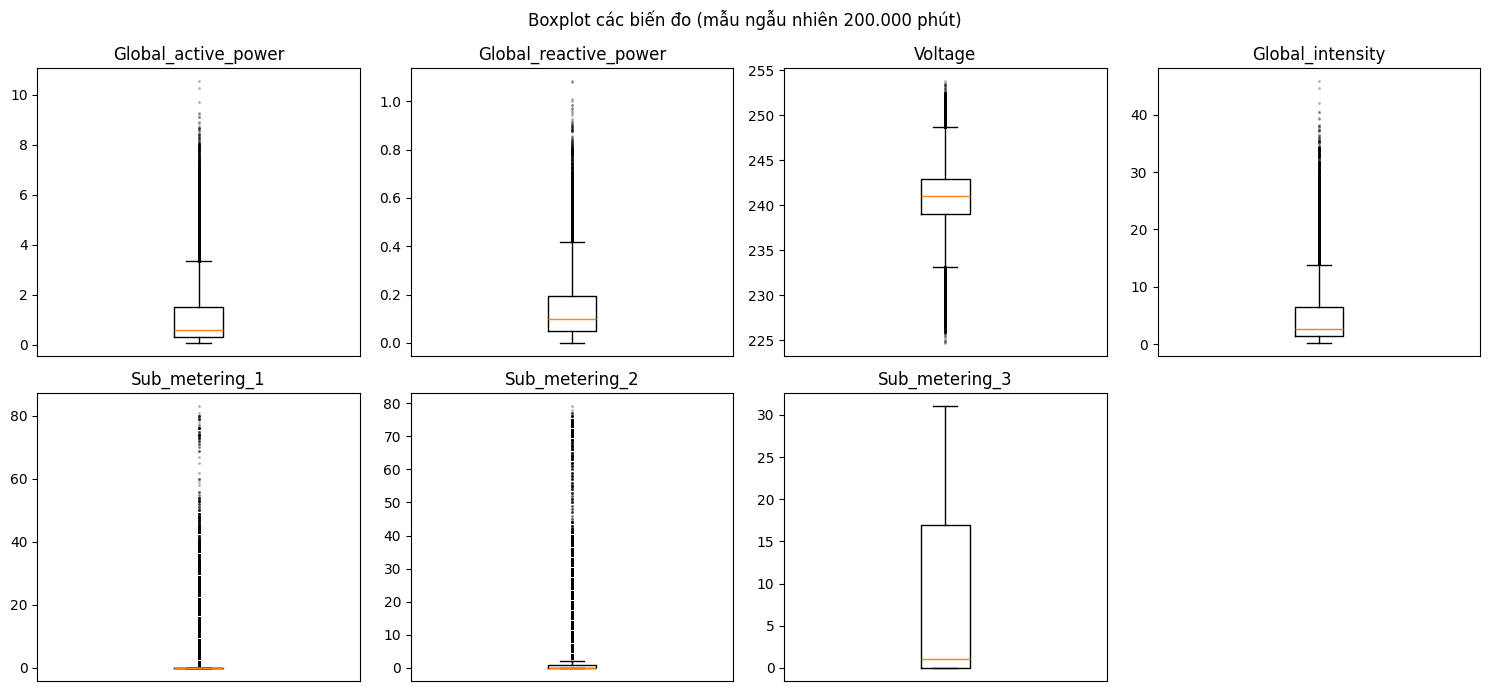

In [11]:
# Boxplot trên mẫu ngẫu nhiên 200.000 phút (seed 42) để vẽ nhanh; bảng IQR ở trên tính trên toàn bộ dữ liệu
samp = frame[COLS].dropna().sample(200_000, random_state=SEED) if frame[COLS].dropna().shape[0] > 200_000 else frame[COLS].dropna()
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for ax, c in zip(axes.ravel(), COLS):
    ax.boxplot(samp[c].values, showfliers=True, flierprops={"markersize": 1, "alpha": 0.3})
    ax.set_title(c); ax.set_xticks([])
axes.ravel()[-1].axis("off")
plt.suptitle("Boxplot các biến đo (mẫu ngẫu nhiên 200.000 phút)")
plt.tight_layout()
plt.savefig(DIR_FIG / "01_boxplot_raw.png", dpi=150)
plt.show()

In [12]:
out_txt = "; ".join(f"{r['Cột']}: {fmt(r['Số ngoại lệ'])} ({r['% ngoại lệ']}%)" for _, r in iqr_tbl.iterrows())
add_qc("Ngoại lệ (IQR / boxplot)",
       f"Số giá trị ngoài ngưỡng 1,5·IQR theo cột: {out_txt}",
       "Chỉ đánh dấu và nhận xét, không xóa. Sub_metering có IQR = 0 nên IQR đánh dấu mọi giá trị khác 0",
       "Đỉnh tiêu thụ cao (bật bếp, nước nóng, điều hòa) là hành vi thật và chính là thứ mô hình cần học; xóa đi sẽ làm mô hình kém ở đúng lúc quan trọng")

## 7. Tổng hợp theo giờ
Quy tắc:
- 4 biến (công suất tác dụng, công suất phản kháng, điện áp, cường độ dòng điện): **trung bình** các phút đo được trong giờ.
- 3 Sub_metering (Wh mỗi phút): **tổng** theo giờ. Viết cách tính là `trung bình các phút đo được × 60`: khi đủ 60 phút thì đúng bằng tổng; khi giờ thiếu vài phút thì không bị thấp giả tạo.
- Một giờ chỉ **hợp lệ** nếu có ít nhất `MIN_VALID_MIN` (30) phút đo được; ngược lại coi là giờ thiếu (NaN).
- Cắt bỏ các giờ thiếu nằm ở hai đầu chuỗi (trước giờ hợp lệ đầu tiên, sau giờ hợp lệ cuối cùng).

In [13]:
g = frame.resample("h")
n_valid = g[TARGET].count().rename("n_valid_min")
hourly = g[MEAN_COLS].mean()
hourly[SUB_COLS] = g[SUB_COLS].mean() * 60
hourly = hourly[COLS]

n_hours_all = len(hourly)
partial_hours = int(((n_valid > 0) & (n_valid < 60)).sum())
low_hours = int(((n_valid > 0) & (n_valid < MIN_VALID_MIN)).sum())   # có dữ liệu nhưng quá ít nên bị loại
hourly.loc[n_valid < MIN_VALID_MIN, COLS] = np.nan

# Cắt hai đầu
valid_pos = hourly.index[hourly[TARGET].notna()]
hourly = hourly.loc[valid_pos[0]:valid_pos[-1]]
n_valid = n_valid.loc[hourly.index]
print("Số giờ sau tổng hợp:", fmt(len(hourly)), "| Từ", hourly.index[0], "đến", hourly.index[-1])
print("Giờ thiếu một phần (1..59 phút đo được):", fmt(partial_hours), "| Giờ bị loại vì < 30 phút:", fmt(low_hours))

## 8. Xử lý thiếu theo giờ: điền tiến tối đa 2 giờ cho đầu vào
- Giữ nguyên 7 cột gốc với NaN ở giờ thiếu: **dùng để làm nhãn** (không bao giờ điền nhãn).
- Tạo 7 cột `*_ffill`: điền tiến tối đa `MAX_FFILL_H` giờ, **dùng làm đầu vào** cho đặc trưng. Điền tiến chỉ dùng giá trị quá khứ nên không rò rỉ thông tin tương lai.
- Cờ `is_missing` (giờ thiếu trong dữ liệu gốc) và `is_filled` (giờ thiếu nhưng đã được điền tiến).
- Phần thiếu còn lại sau điền tiến để nguyên NaN, Nhung sẽ điền trung vị học từ Train trong pipeline mô hình.

In [14]:
for c in COLS:
    hourly[c + "_ffill"] = hourly[c].ffill(limit=MAX_FFILL_H)

is_missing = hourly[COLS].isna().all(axis=1)
is_filled = is_missing & hourly[TARGET + "_ffill"].notna()
still_nan = hourly[TARGET + "_ffill"].isna()

# Kiểm tra: ở giờ không thiếu thì cột ffill phải bằng cột gốc
ok = ~is_missing
assert np.allclose(hourly.loc[ok, COLS].to_numpy(),
                   hourly.loc[ok, [c + "_ffill" for c in COLS]].to_numpy(), equal_nan=True)

# Thống kê khoảng thiếu theo giờ
sh, lh = runs(is_missing.to_numpy())
n_gaps_h = len(sh)
longest_h = int(lh.max()) if n_gaps_h else 0
n_gaps_le2 = int((lh <= MAX_FFILL_H).sum())
n_gaps_gt2 = int((lh > MAX_FFILL_H).sum())
n_missing_h = int(is_missing.sum())
n_filled_h = int(is_filled.sum())
n_still_h = int(still_nan.sum())
n_hours = len(hourly)
print(f"Tổng số giờ: {fmt(n_hours)}")
print(f"Giờ thiếu: {fmt(n_missing_h)} ({n_missing_h/n_hours*100:.2f}%) trong {n_gaps_h} khoảng, dài nhất {longest_h} giờ")
print(f"Khoảng thiếu <= {MAX_FFILL_H} giờ: {n_gaps_le2} | > {MAX_FFILL_H} giờ: {n_gaps_gt2}")
print(f"Giờ đã điền tiến: {fmt(n_filled_h)} | Giờ còn NaN sau điền tiến: {fmt(n_still_h)} ({n_still_h/n_hours*100:.2f}%)")

In [15]:
add_qc("Tổng hợp theo giờ",
       f"{fmt(n_hours)} giờ (từ {hourly.index[0]:%d/%m/%Y %H:%M} đến {hourly.index[-1]:%d/%m/%Y %H:%M}); "
       f"{fmt(partial_hours)} giờ có dữ liệu một phần (1 đến 59 phút), {fmt(low_hours)} giờ có dưới {MIN_VALID_MIN} phút bị coi là thiếu",
       "Trung bình cho công suất tác dụng, công suất phản kháng, điện áp, cường độ; tổng (trung bình × 60) cho 3 Sub_metering; giờ hợp lệ khi có >= 30 phút đo được",
       "Mục tiêu đề tài là dự báo công suất trung bình theo giờ; Sub_metering là Wh mỗi phút nên cộng dồn theo giờ")
add_qc("Xử lý thiếu ở mức giờ",
       f"{fmt(n_missing_h)} giờ thiếu ({n_missing_h/n_hours*100:.2f}%) trong {n_gaps_h} khoảng, dài nhất {longest_h} giờ; "
       f"{n_gaps_le2} khoảng <= {MAX_FFILL_H} giờ, {n_gaps_gt2} khoảng > {MAX_FFILL_H} giờ. "
       f"Đã điền tiến {fmt(n_filled_h)} giờ; còn {fmt(n_still_h)} giờ NaN ({n_still_h/n_hours*100:.2f}%)",
       "Cột gốc giữ NaN (làm nhãn). Cột *_ffill điền tiến tối đa 2 giờ (làm đầu vào). Có cờ is_missing, is_filled. Phần NaN còn lại: Nhung điền trung vị học từ Train trong pipeline",
       "Nhãn không được điền; điền tiến chỉ dùng quá khứ nên không rò rỉ; điền trung vị phải fit trên Train nên không làm ở bước làm sạch")

## 9. Lưu kết quả và kiểm tra lại

In [16]:
out = hourly[COLS + [c + "_ffill" for c in COLS]].copy()
out["n_valid_min"] = n_valid.astype(int)
out["is_missing"] = is_missing.astype(int)
out["is_filled"] = is_filled.astype(int)
out.to_csv(DIR_PROC / "hourly_clean.csv", index_label="datetime", float_format="%.4f")

chk = pd.read_csv(DIR_PROC / "hourly_clean.csv", parse_dates=["datetime"], index_col="datetime")
print("Đã lưu:", DIR_PROC / "hourly_clean.csv")
print("Kích thước:", chk.shape, "| Trục giờ liên tục:", bool((chk.index.to_series().diff().dropna() == pd.Timedelta(hours=1)).all()))
print("Các cột:", list(chk.columns))
chk.head()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Global_active_power_ffill,Global_reactive_power_ffill,Voltage_ffill,Global_intensity_ffill,Sub_metering_1_ffill,Sub_metering_2_ffill,Sub_metering_3_ffill,n_valid_min,is_missing,is_filled
datetime,,,,,,,,,,,,,,,,,
2006-12-16 17:00:00,4.2229,0.2290,234.6439,18.1000,0.0,31.6667,1011.6667,4.2229,0.2290,234.6439,18.1000,0.0,31.6667,1011.6667,36,0,0
2006-12-16 18:00:00,3.6322,0.0800,234.5802,15.6000,0.0,403.0000,1012.0000,3.6322,0.0800,234.5802,15.6000,0.0,403.0000,1012.0000,60,0,0
2006-12-16 19:00:00,3.4002,0.0852,233.2325,14.5033,0.0,86.0000,1001.0000,3.4002,0.0852,233.2325,14.5033,0.0,86.0000,1001.0000,60,0,0
2006-12-16 20:00:00,3.2686,0.0751,234.0715,13.9167,0.0,0.0000,1007.0000,3.2686,0.0751,234.0715,13.9167,0.0,0.0000,1007.0000,60,0,0
2006-12-16 21:00:00,3.0565,0.0767,237.1587,13.0467,0.0,25.0000,1033.0000,3.0565,0.0767,237.1587,13.0467,0.0,25.0000,1033.0000,60,0,0


In [17]:
qc_df = pd.DataFrame(qc)
qc_df.to_csv(DIR_DATA / "quality_control_table.csv", index=False, encoding="utf-8-sig")

lines = ["| " + " | ".join(qc_df.columns) + " |", "|" + "---|" * len(qc_df.columns)]
for _, r in qc_df.iterrows():
    lines.append("| " + " | ".join(str(v).replace("|", "/") for v in r.values) + " |")
(DIR_DATA / "quality_control_table.md").write_text("\n".join(lines), encoding="utf-8")

pd.set_option("display.max_colwidth", None)
qc_df

,Kiểm tra,Kết quả (số thật),Cách xử lý,Lý do
0,"Số dòng, số cột thực tế","2.075.259 dòng, 9 cột. Khớp với Proposal (2.075.259 dòng)",Giữ nguyên,"Tự đếm bằng code để đối chiếu, không chép số từ Proposal"
1,"Kiểu dữ liệu, định dạng","7 cột đo đọc thành số thực (float64); Date và Time là chuỗi, đã gộp thành datetime theo định dạng dd/mm/yyyy hh:mm:ss",Chuyển ký tự '?' thành NaN; gộp Date và Time thành chỉ mục thời gian,Mô hình và resample cần kiểu số và kiểu thời gian
2,Dòng trùng lặp,0 dòng trùng hoàn toàn; 0 mốc thời gian bị lặp,Không có gì cần xóa,Dòng lặp làm sai thống kê và sai khi tổng hợp theo giờ
3,Tính liên tục thời gian,"Từ 16/12/2006 17:24 đến 26/11/2010 21:02: cần 2.075.259 mốc phút, tệp có 2.075.259; thiếu hẳn 0 mốc","Không cần xử lý, trục thời gian đã đầy đủ","Trục thời gian liên tục là điều kiện để tạo lag, rolling đúng nghĩa"
4,Giá trị thiếu ('?'),"Mỗi cột đo thiếu 25.979 giá trị (1.252%); cả 7 cột thiếu đồng thời trên cùng một dòng. Có 71 khoảng thiếu liên tục, dài nhất 7.226 phút (~120.4 giờ); 7 khoảng dài hơn 2 giờ","Không điền nhãn mục tiêu. Với đầu vào: điền tiến tối đa 2 giờ, thêm cờ báo thiếu; phần còn lại giữ NaN (Nhung điền trung vị học từ Train trong pipeline mô hình)","Điền nhãn sẽ làm sai kết quả đánh giá. Điền tiến chỉ dùng quá khứ nên không rò rỉ. Khoảng thiếu dài (nhiều giờ, nhiều ngày) không thể điền hợp lý"
5,Miền giá trị hợp lý,"Công suất âm: 0; Global_intensity âm: 0; Sub_metering âm: 0; Global_active_power = 0: 0 phút; Voltage ngoài [200, 260] V: 0 phút; phút có tổng 3 công tơ phụ lớn hơn điện năng cả hộ: 1.050","Chỉ ghi nhận, không xóa. Nếu có giá trị vi phạm thì nhận xét nguyên nhân trong báo cáo",Giá trị vi phạm miền vật lý là dấu hiệu lỗi đo; còn giá trị cao nhưng hợp lý là tiêu thụ thật
6,Ngoại lệ (IQR / boxplot),"Số giá trị ngoài ngưỡng 1,5·IQR theo cột: Global_active_power: 94.907 (4.63%); Global_reactive_power: 40.420 (1.97%); Voltage: 51.067 (2.49%); Global_intensity: 100.961 (4.93%); Sub_metering_1: 169.105 (8.25%); Sub_metering_2: 77.151 (3.76%); Sub_metering_3: 0 (0.0%)","Chỉ đánh dấu và nhận xét, không xóa. Sub_metering có IQR = 0 nên IQR đánh dấu mọi giá trị khác 0","Đỉnh tiêu thụ cao (bật bếp, nước nóng, điều hòa) là hành vi thật và chính là thứ mô hình cần học; xóa đi sẽ làm mô hình kém ở đúng lúc quan trọng"
7,Tổng hợp theo giờ,"34.588 giờ (từ 16/12/2006 17:00 đến 26/11/2010 20:00); 83 giờ có dữ liệu một phần (1 đến 59 phút), 11 giờ có dưới 30 phút bị coi là thiếu","Trung bình cho công suất tác dụng, công suất phản kháng, điện áp, cường độ; tổng (trung bình × 60) cho 3 Sub_metering; giờ hợp lệ khi có >= 30 phút đo được",Mục tiêu đề tài là dự báo công suất trung bình theo giờ; Sub_metering là Wh mỗi phút nên cộng dồn theo giờ
8,Xử lý thiếu ở mức giờ,"431 giờ thiếu (1.25%) trong 12 khoảng, dài nhất 120 giờ; 5 khoảng <= 2 giờ, 7 khoảng > 2 giờ. Đã điền tiến 20 giờ; còn 411 giờ NaN (1.19%)","Cột gốc giữ NaN (làm nhãn). Cột *_ffill điền tiến tối đa 2 giờ (làm đầu vào). Có cờ is_missing, is_filled. Phần NaN còn lại: Nhung điền trung vị học từ Train trong pipeline",Nhãn không được điền; điền tiến chỉ dùng quá khứ nên không rò rỉ; điền trung vị phải fit trên Train nên không làm ở bước làm sạch


## Nhật ký

- 01/11/2026 – Đưa notebook làm sạch, xử lý thiếu và tổng hợp theo giờ lên repo (qua web). Commit `7bdea77`, `bf2cddc`.
- 13/11/2026 – Thêm ô ghi log ở đầu notebook; xoá mục 10 (in lại tóm tắt số liệu) vì các số này đã có trong bảng kiểm soát chất lượng ở mục 9; chạy lại lúc 19:40, `hourly_clean.csv` không đổi. Commit `9a7cfb7`.